Tracking using Template Matching (5).
Search Window: 100x100. Template Size: 20x20
Template extracted successfully (20x20) from center.

Tracking Complete. Plotting results...


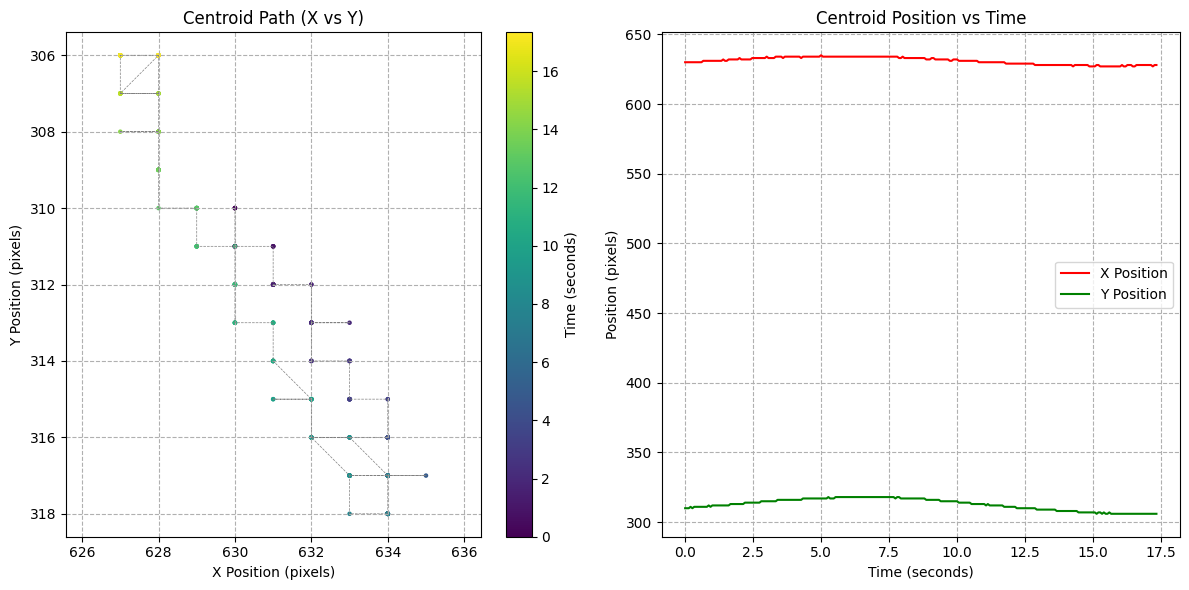

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import math

# Expected position of the center => will start the region of interest around this
CENTER_X_EXPECTED = 630
CENTER_Y_EXPECTED = 310

TEMPLATE_SIZE = 20  
SEARCH_WINDOW_SIZE = 100 

# egion of intest
ROI_START_X = CENTER_X_EXPECTED - (SEARCH_WINDOW_SIZE // 2)
ROI_START_Y = CENTER_Y_EXPECTED - (SEARCH_WINDOW_SIZE // 2)
ROI_WIDTH = SEARCH_WINDOW_SIZE
ROI_HEIGHT = SEARCH_WINDOW_SIZE

FPS_SAMPLE_RATE = 15.0    
MATCH_METHOD = cv2.TM_CCOEFF_NORMED 

# velocity constraint => maximum allowed movement per second
MAX_VELOCITY_PPS = 50.0 


def calculate_distance(p1, p2):
    # euclidean distance
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)


def track_dark_spot_template_match(video_path, roi_x, roi_y, roi_w, roi_h, template_size, fps_sample_rate):
    """
    Tracks a dark spot using Template Matching within a fixed search ROI, 
    including a velocity constraint check.
    """
    cap = cv2.VideoCapture(video_path)

    frame_rate = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_step = max(1, int(frame_rate / fps_sample_rate))
    
    # initial template extraction
    ret, initial_frame = cap.read()
    if not ret: return []

    t_start_x = CENTER_X_EXPECTED - (template_size // 2)
    t_start_y = CENTER_Y_EXPECTED - (template_size // 2)
    template_bgr = initial_frame[t_start_y:t_start_y + template_size, t_start_x:t_start_x + template_size]
    template = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
    
    if template.shape[0] != template_size:
        print("Could not extract template.")
        return []
        
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0) 
    
    # general tracking
    tracking_data = []
    frame_count = 0
    start_x, start_y = roi_x, roi_y
    end_x = start_x + roi_w
    end_y = start_y + roi_h
    
    # velocity tracking
    last_cX, last_cY = None, None
    last_time_s = -1.0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        if frame_count % frame_step == 0:
            current_time_s = frame_count / frame_rate
            
            # Template matching
            search_area_bgr = frame[start_y:end_y, start_x:end_x]
            search_area = cv2.cvtColor(search_area_bgr, cv2.COLOR_BGR2GRAY)
            
            result_map = cv2.matchTemplate(search_area, template, MATCH_METHOD)
            _, max_val, _, max_loc = cv2.minMaxLoc(result_map)

            top_left_x_roi, top_left_y_roi = max_loc

            # initial position
            new_cX_orig = top_left_x_roi + start_x + (template_size // 2)
            new_cY_orig = top_left_y_roi + start_y + (template_size // 2)
            
            cX_orig, cY_orig = new_cX_orig, new_cY_orig 

            # velocity constraint check
            if last_cX is not None:
                delta_time = current_time_s - last_time_s
                
                if delta_time > 0.001: 
                    max_distance_allowed = MAX_VELOCITY_PPS * delta_time
                    actual_distance = calculate_distance((new_cX_orig, new_cY_orig), (last_cX, last_cY))
                    
                    # check constraint
                    if actual_distance > max_distance_allowed:
                        cX_orig = last_cX
                        cY_orig = last_cY

            # record the accepted (or previous) position
            tracking_data.append((current_time_s, cX_orig, cY_orig))

            # Update the last known good position for the next frame's check
            last_cX, last_cY = cX_orig, cY_orig
            last_time_s = current_time_s
            
            cv2.circle(frame, (cX_orig, cY_orig), 5, (0, 255, 0), -1) 
            cv2.rectangle(frame, (start_x, start_y), (end_x, end_y), (255, 0, 0), 2) 
            cv2.putText(frame, f"Match Score: {max_val:.3f}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
            
            match_bottom_right = (top_left_x_roi + template_size, top_left_y_roi + template_size)
            match_vis = search_area_bgr.copy()
            cv2.rectangle(match_vis, max_loc, match_bottom_right, (0, 255, 255), 2)
            cv2.putText(match_vis, f"Match: {max_val:.3f}", (5, match_vis.shape[0]-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
            
            cv2.imshow("Template Match Verification (ROI only)", match_vis)
            cv2.imshow("Tracking Result", frame)
            
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break

        frame_count += 1

    cap.release()
    cv2.destroyAllWindows()
    return tracking_data


def plot_tracking_results(tracking_data):
    time_s = np.array([d[0] for d in tracking_data])
    x_pos = np.array([d[1] for d in tracking_data])
    y_pos = np.array([d[2] for d in tracking_data])

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.scatter(x_pos, y_pos, c=time_s, cmap='viridis', s=5, label='Time Progression')
    plt.plot(x_pos, y_pos, linestyle='--', color='gray', linewidth=0.5)
    plt.colorbar(label='Time (seconds)')
    plt.title('Centroid Path (X vs Y)')
    plt.xlabel('X Position (pixels)')
    plt.ylabel('Y Position (pixels)')
    plt.gca().invert_yaxis() 
    plt.grid(True, linestyle='--')
    plt.axis('equal') 
    
    plt.subplot(1, 2, 2)
    plt.plot(time_s, x_pos, label='X Position', color='red')
    plt.plot(time_s, y_pos, label='Y Position', color='green')
    plt.title('Centroid Position vs Time')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Position (pixels)')
    plt.legend()
    plt.grid(True, linestyle='--')
    
    plt.tight_layout()
    plt.show()

if __name__ == '__main__':
    video_file = 'video_2b.mp4' 
    
    if os.path.exists(video_file):
        results = track_dark_spot_template_match(
            video_file,
            roi_x=ROI_START_X,
            roi_y=ROI_START_Y,
            roi_w=ROI_WIDTH,
            roi_h=ROI_HEIGHT,
            template_size=TEMPLATE_SIZE,
            fps_sample_rate=FPS_SAMPLE_RATE
        )

        if results:
            plot_tracking_results(results)